# Notebook 05 — Final Evaluation & Comparison
**Goal:** Compare all models side-by-side, generate final confusion matrices,
and produce Grad-CAM visualizations to interpret what the vision branch focuses on.

In [1]:
import os, warnings, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

TARGET_NAMES = ['Fresh', 'Formalin-Mixed', 'Rotten']
SENSOR_COLS = ['Moisture', 'Firmness', 'pH', 'TSS', 'Ethanol', 'CO2', 'Formaldehyde']
RESULTS_DIR = '../results'
MODELS_DIR = '../models'
IMG_SIZE = 224
EMBED_DIM = 64

## 1. Load Sensor Baseline Results

In [2]:
sensor_results = pd.read_csv(os.path.join(RESULTS_DIR, 'sensor_baselines.csv'))
print("Sensor-only baselines:")
print(sensor_results[['Model', 'Accuracy (%)', 'Macro F1']].to_string(index=False))

Sensor-only baselines:
        Model  Accuracy (%)  Macro F1
Random Forest         100.0       1.0
      XGBoost         100.0       1.0
     LightGBM         100.0       1.0
   Sensor MLP         100.0       1.0


## 2. Re-evaluate Vision Baseline on Test Set

In [3]:
class LitchiImageDataset(Dataset):
    def __init__(self, csv_path, transform=None):
        self.df = pd.read_csv(csv_path)
        self.transform = transform
        self.labels = self.df['label'].values
        self.paths = self.df['image_path'].values
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, torch.tensor(self.labels[idx], dtype=torch.long)

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
test_img_ds = LitchiImageDataset('../data/processed/test.csv', val_transform)
test_img_loader = DataLoader(test_img_ds, batch_size=32, shuffle=False)

# Load vision model
vis_model = models.mobilenet_v3_small(weights=None)
in_features = vis_model.classifier[0].in_features
vis_model.classifier = nn.Sequential(
    nn.Linear(in_features, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, 3)
)
vis_model.load_state_dict(torch.load(os.path.join(MODELS_DIR, "vision_baseline.pth"), weights_only=True))
vis_model.eval()

vis_preds, vis_labels = [], []
with torch.no_grad():
    for imgs, labels in test_img_loader:
        vis_preds.extend(vis_model(imgs).argmax(1).numpy())
        vis_labels.extend(labels.numpy())
vis_acc = accuracy_score(vis_labels, vis_preds)
vis_f1 = f1_score(vis_labels, vis_preds, average='macro')
print(f"Vision Baseline  ->  Accuracy: {vis_acc*100:.2f}%  |  Macro F1: {vis_f1:.4f}")

Vision Baseline  ->  Accuracy: 98.44%  |  Macro F1: 0.9844


## 3. Re-evaluate GMU Fusion on Test Set

In [4]:
class LitchiMultimodalDataset(Dataset):
    def __init__(self, csv_path, scaler=None, transform=None):
        self.df = pd.read_csv(csv_path)
        self.transform = transform
        self.paths = self.df['image_path'].values
        self.labels = self.df['label'].values
        raw_sensor = self.df[SENSOR_COLS].values.astype(np.float32)
        self.sensor_data = scaler.transform(raw_sensor) if scaler else raw_sensor
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        sensor = torch.tensor(self.sensor_data[idx], dtype=torch.float32)
        return img, sensor, torch.tensor(self.labels[idx], dtype=torch.long)

# Load scaler
with open(os.path.join(MODELS_DIR, "sensor_scaler.pkl"), "rb") as f:
    scaler = pickle.load(f)

test_mm_ds = LitchiMultimodalDataset('../data/processed/test.csv', scaler=scaler, transform=val_transform)
test_mm_loader = DataLoader(test_mm_ds, batch_size=32, shuffle=False)

# Load GMU model
class MultimodalGMU(nn.Module):
    def __init__(self, embed_dim=64, num_classes=3):
        super().__init__()
        backbone = models.mobilenet_v3_small(weights=None)
        vis_in = backbone.classifier[0].in_features
        backbone.classifier = nn.Identity()
        self.vision_backbone = backbone
        self.vision_proj = nn.Sequential(
            nn.Linear(vis_in, embed_dim), nn.BatchNorm1d(embed_dim), nn.ReLU(), nn.Dropout(0.3))
        self.sensor_branch = nn.Sequential(
            nn.Linear(7, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(64, embed_dim), nn.BatchNorm1d(embed_dim), nn.ReLU())
        self.gate = nn.Sequential(nn.Linear(embed_dim * 2, embed_dim), nn.Sigmoid())
        self.classifier = nn.Sequential(
            nn.Linear(embed_dim, 32), nn.ReLU(), nn.Dropout(0.2), nn.Linear(32, num_classes))
    def forward(self, img, sensor):
        h_v = self.vision_proj(self.vision_backbone(img))
        h_s = self.sensor_branch(sensor)
        g = self.gate(torch.cat([h_v, h_s], dim=1))
        return self.classifier(g * h_v + (1 - g) * h_s)
    def get_gate_values(self, img, sensor):
        with torch.no_grad():
            h_v = self.vision_proj(self.vision_backbone(img))
            h_s = self.sensor_branch(sensor)
            return self.gate(torch.cat([h_v, h_s], dim=1))

gmu_model = MultimodalGMU(embed_dim=EMBED_DIM)
gmu_model.load_state_dict(torch.load(os.path.join(MODELS_DIR, "multimodal_gmu.pth"), weights_only=True))
gmu_model.eval()

gmu_preds, gmu_labels = [], []
with torch.no_grad():
    for imgs, sensors, labels in test_mm_loader:
        gmu_preds.extend(gmu_model(imgs, sensors).argmax(1).numpy())
        gmu_labels.extend(labels.numpy())
gmu_acc = accuracy_score(gmu_labels, gmu_preds)
gmu_f1 = f1_score(gmu_labels, gmu_preds, average='macro')
print(f"GMU Fusion  ->  Accuracy: {gmu_acc*100:.2f}%  |  Macro F1: {gmu_f1:.4f}")

GMU Fusion  ->  Accuracy: 99.78%  |  Macro F1: 0.9978


## 4. Full Comparison Table

In [5]:
# Combine all results
all_results = sensor_results.copy()
all_results = pd.concat([all_results, pd.DataFrame([
    {'Model': 'Vision Baseline (MobileNet-V3)', 'Accuracy': vis_acc, 'Macro_F1': vis_f1,
     'Accuracy (%)': round(vis_acc*100, 2), 'Macro F1': round(vis_f1, 4)},
    {'Model': 'GMU Fusion (Ours)', 'Accuracy': gmu_acc, 'Macro_F1': gmu_f1,
     'Accuracy (%)': round(gmu_acc*100, 2), 'Macro F1': round(gmu_f1, 4)},
])], ignore_index=True)

print("=" * 60)
print("          FULL MODEL COMPARISON")
print("=" * 60)
print(all_results[['Model', 'Accuracy (%)', 'Macro F1']].to_string(index=False))

all_results.to_csv(os.path.join(RESULTS_DIR, 'comparison_table.csv'), index=False)
print(f"\nSaved to {RESULTS_DIR}/comparison_table.csv")

          FULL MODEL COMPARISON
                         Model  Accuracy (%)  Macro F1
                 Random Forest        100.00    1.0000
                       XGBoost        100.00    1.0000
                      LightGBM        100.00    1.0000
                    Sensor MLP        100.00    1.0000
Vision Baseline (MobileNet-V3)         98.44    0.9844
             GMU Fusion (Ours)         99.78    0.9978

Saved to ../results/comparison_table.csv


## 5. Confusion Matrices Side by Side

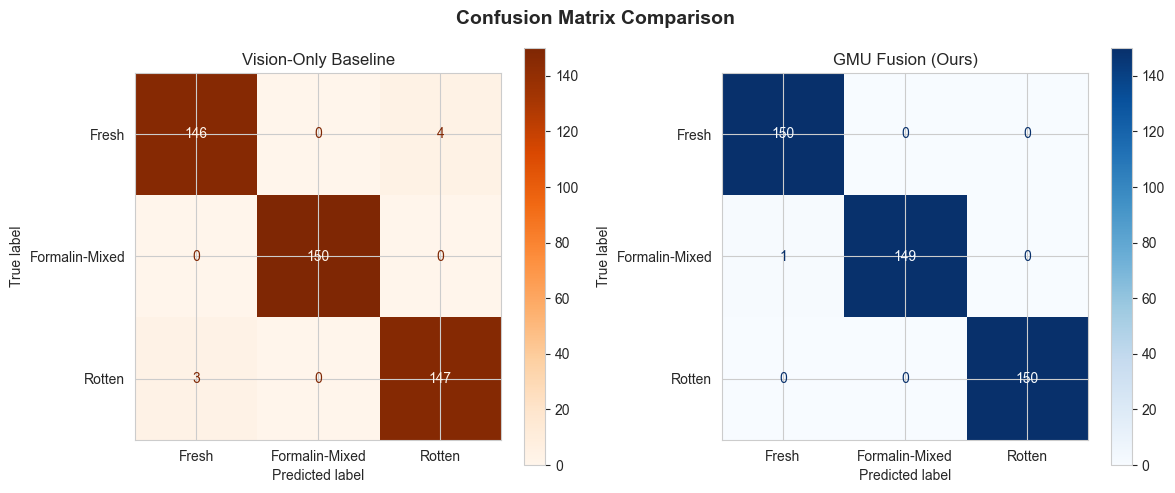

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

cm_vis = confusion_matrix(vis_labels, vis_preds)
ConfusionMatrixDisplay(cm_vis, display_labels=TARGET_NAMES).plot(ax=ax1, cmap="Oranges")
ax1.set_title("Vision-Only Baseline")

cm_gmu = confusion_matrix(gmu_labels, gmu_preds)
ConfusionMatrixDisplay(cm_gmu, display_labels=TARGET_NAMES).plot(ax=ax2, cmap="Blues")
ax2.set_title("GMU Fusion (Ours)")

plt.suptitle("Confusion Matrix Comparison", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'confusion_matrices.png'), bbox_inches='tight')
plt.show()

## 6. Gate Analysis
Visualize how the GMU gate balances vision vs sensor trust per class.

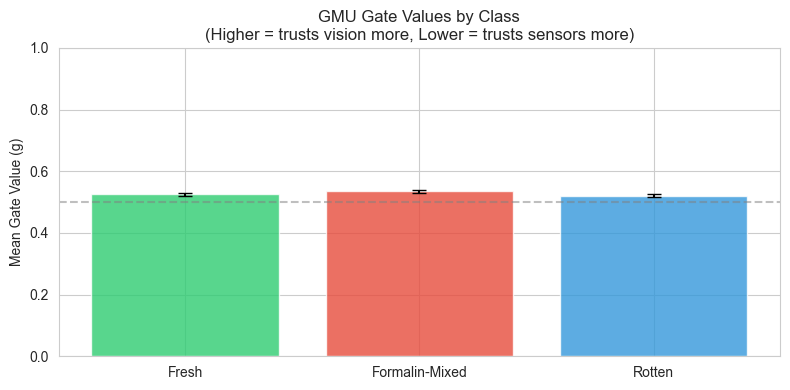

Fresh: gate mean = 0.525 (vision weight)
Formalin-Mixed: gate mean = 0.535 (vision weight)
Rotten: gate mean = 0.520 (vision weight)


In [7]:
# Collect gate values per class
gate_data = {cat: [] for cat in TARGET_NAMES}
gmu_model.eval()
with torch.no_grad():
    for imgs, sensors, labels in test_mm_loader:
        gates = gmu_model.get_gate_values(imgs, sensors).mean(dim=1).numpy()
        for g_val, lbl in zip(gates, labels.numpy()):
            gate_data[TARGET_NAMES[lbl]].append(g_val)

fig, ax = plt.subplots(figsize=(8, 4))
positions = range(len(TARGET_NAMES))
means = [np.mean(gate_data[c]) for c in TARGET_NAMES]
stds = [np.std(gate_data[c]) for c in TARGET_NAMES]
ax.bar(positions, means, yerr=stds, capsize=5, color=['#2ecc71', '#e74c3c', '#3498db'], alpha=0.8)
ax.set_xticks(positions)
ax.set_xticklabels(TARGET_NAMES)
ax.set_ylabel("Mean Gate Value (g)")
ax.set_title("GMU Gate Values by Class\n(Higher = trusts vision more, Lower = trusts sensors more)")
ax.axhline(y=0.5, color="gray", linestyle="--", alpha=0.5)
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'gate_analysis.png'), bbox_inches='tight')
plt.show()

for cat in TARGET_NAMES:
    print(f"{cat}: gate mean = {np.mean(gate_data[cat]):.3f} (vision weight)")

## 7. Classification Reports

In [8]:
print("Vision Baseline — Classification Report:")
print(classification_report(vis_labels, vis_preds, target_names=TARGET_NAMES))
print("\n" + "="*60 + "\n")
print("GMU Fusion — Classification Report:")
print(classification_report(gmu_labels, gmu_preds, target_names=TARGET_NAMES))

Vision Baseline — Classification Report:
                precision    recall  f1-score   support

         Fresh       0.98      0.97      0.98       150
Formalin-Mixed       1.00      1.00      1.00       150
        Rotten       0.97      0.98      0.98       150

      accuracy                           0.98       450
     macro avg       0.98      0.98      0.98       450
  weighted avg       0.98      0.98      0.98       450



GMU Fusion — Classification Report:
                precision    recall  f1-score   support

         Fresh       0.99      1.00      1.00       150
Formalin-Mixed       1.00      0.99      1.00       150
        Rotten       1.00      1.00      1.00       150

      accuracy                           1.00       450
     macro avg       1.00      1.00      1.00       450
  weighted avg       1.00      1.00      1.00       450



---
## Summary

**Key files for Streamlit deployment:**
- `models/multimodal_gmu.pth` — trained model weights
- `models/sensor_scaler.pkl` — fitted StandardScaler for sensor inputs
- Copy the `MultimodalGMU` class definition into your Streamlit app

**Project complete.**